# Explore here
## Importar datos y análisis superficial

In [129]:
# Your code here
import pandas as pd
import numpy as np
ruta = 'https://breathecode.herokuapp.com/asset/internal-link?id=929&path=medical_insurance_cost.csv'
df = pd.read_csv(ruta)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [130]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [131]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [132]:
df.shape

(1338, 7)

In [133]:
df.duplicated().sum() #comprobacion de duplicados

np.int64(1)

In [134]:
df = df.drop_duplicates() # eliminar la fila duplicada
df.shape # shape para comprobar la eliminacion de la fila duplicada

(1337, 7)

Variables del conjunto de datos:

- age: Edad del beneficiario principal (numérico)
- sex: Género del beneficiario principal (categórico)
- bmi: índice de masa corporal (numérico)
- children: Número de niños/dependientes cubiertos por un seguro médico (numérico)
- smoker: ¿Es fumador? (categórico)
- region: Área residencial del beneficiario en USA: noreste, sureste, suroeste, noroeste (categórico)
- charges: Prima del seguro médico (numérico)

Estamos ante un conjunto de datos con muy pocas variables, que tiene un total de 1338 registros.

No hay presencia de valores nulos, que facilitará la posterior limpieza y preparación para entrenar al modelo.

La variable charges es claramente nuestra variable objetivo, ya que representa el coste del seguro de cada paciente.

La estadística descriptiva no ha revelado ningún dato que llame la atención sobre algún tipo de inconsistencia en los datos.

## Exploración de datos
### Variables univariantes
Vamos a estudiar las 3 variables categóricas: sex, smoker y region

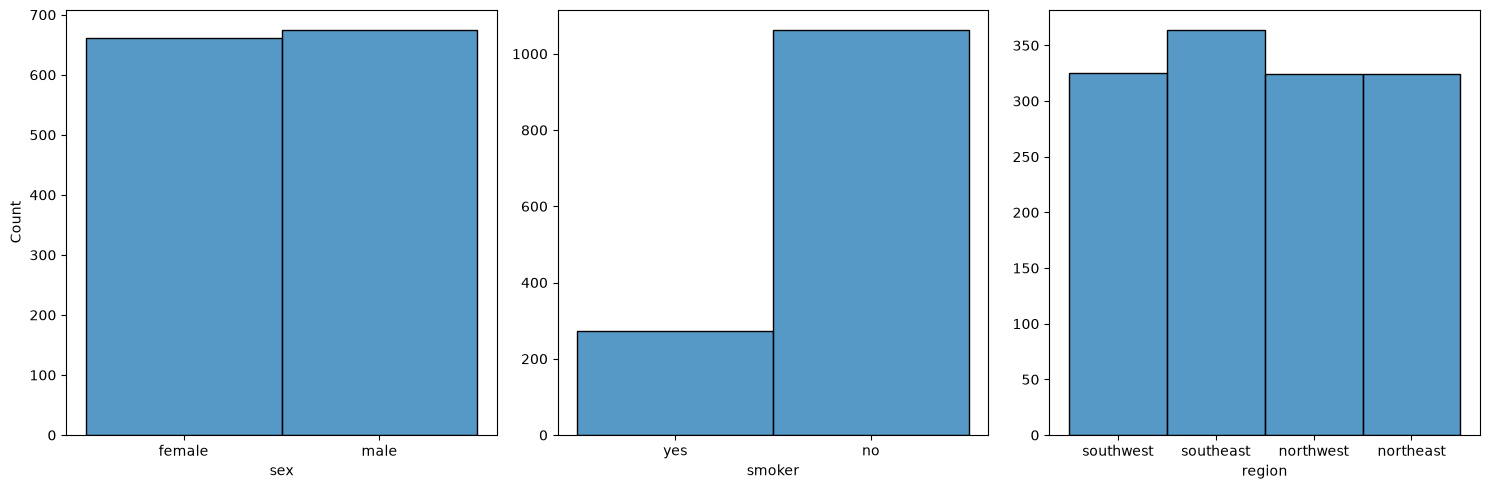

In [135]:
#importo librerias para graficar 
import matplotlib.pyplot as plt
import seaborn as sns

# graficamos
fig, axis = plt.subplots(1, 3, figsize=(15, 5))

# Crear un histograma múltiple
sns.histplot(ax = axis[0], data = df, x = "sex")
sns.histplot(ax = axis[1], data = df, x = "smoker").set(ylabel = None)
sns.histplot(ax = axis[2], data = df, x = "region").set(ylabel = None)

# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

- La variable del sexo está bastante equilibrada. Hay una ligera superioridad en la cantidad de hombres pero nada especial para destacar.
- Casi todos los clientes son no fumadores. Apenas un poco más de 1/5 de las personas fuman.
- Al igual que el sexo, la variable de la región está muy equilibrada. Encontramos que el sureste tiene una ligera superioridad frente al resto, pero nada destacable.

### Variables numéricas
Son age, bmi, children y charges. Vamos a ver cada una con un histograma y uno de caja.

In [136]:
df.info() # info para verificar cuales eran numericas 

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 83.6 KB


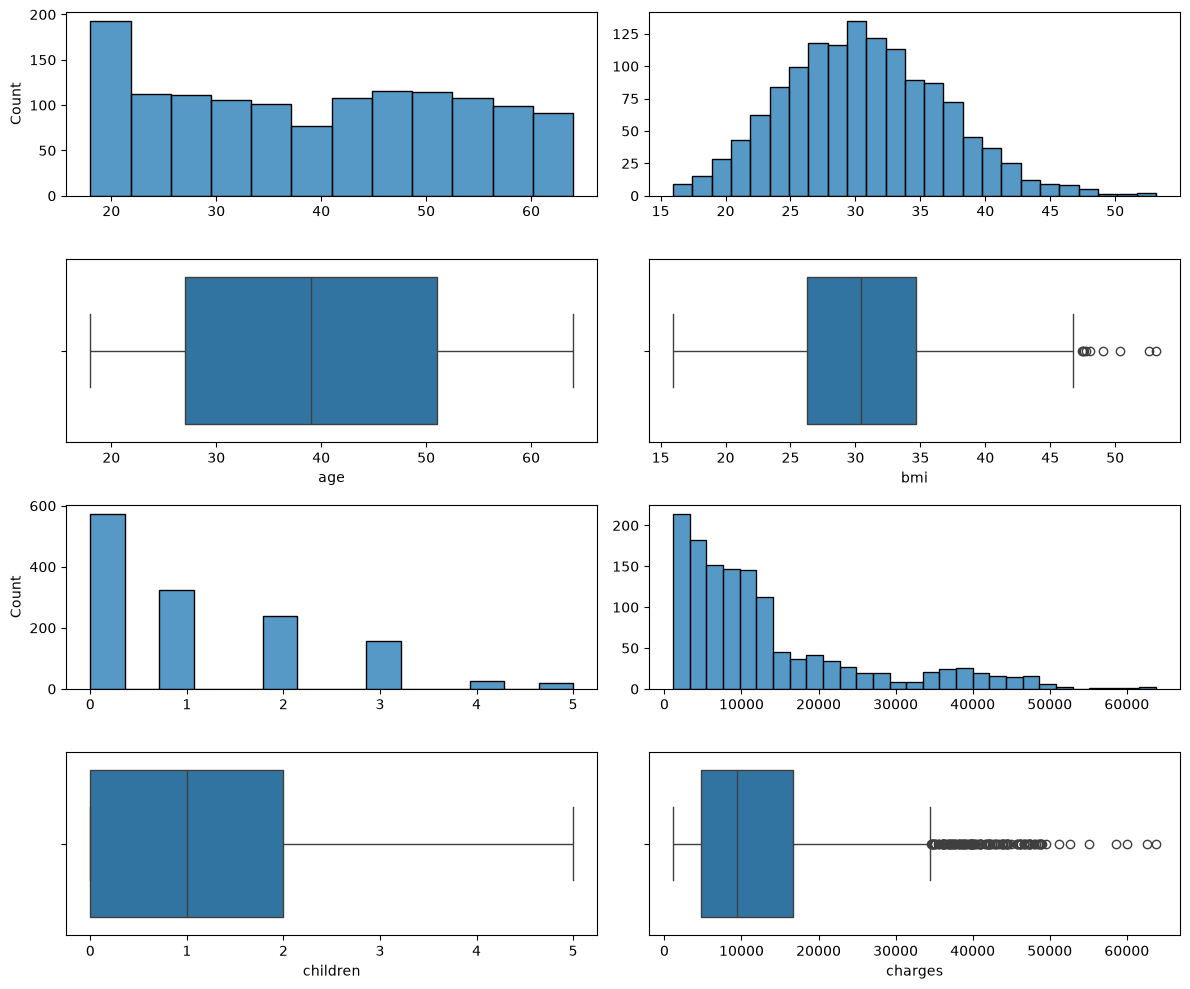

In [137]:
fig, axis = plt.subplots(4, 2, figsize = (12, 10))


sns.histplot(ax = axis[0, 0], data = df, x = "age").set(xlabel = None)
sns.boxplot(ax = axis[1, 0], data = df, x = "age")

sns.histplot(ax = axis[0, 1], data = df, x = "bmi").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 1], data = df, x = "bmi")

sns.histplot(ax = axis[2, 0], data = df, x = "children").set(xlabel = None)
sns.boxplot(ax = axis[3, 0], data = df, x = "children")

sns.histplot(ax = axis[2, 1], data = df, x = "charges").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 1], data = df, x = "charges")

# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

- El mayor pico de edad de los clientes se produce en los 20 años. A partir de ahí, las edades están bastante equilibradas hasta llegar a los 60 años, edad de la cual no se han obtenido valores superiores.

- El BMI es bastante simétrico, teniendo el pico en los 30 puntos.

- La gran mayoría de clientes no tiene hijos. En cuanto a la gente con hijos, vemos como cada vez hay menos gente según aumenta la cantidad de hijos.

- Mucha gente tiene primas inferiores a los 10.000. De los 10.000 a 20.000 vemos como decae enormemente la cantidad de gente con primas tan altas, cantidad que se mantiene increíblemente baja hasta los 50.000, habiendo un ligero aumento entorno a los 40.000. Los outliers nos muestran que hay una minoría que llega a tener primas de 60.000.

### Análisis de variables multivariante
Vamos a ver la relación entre las variables numéricas, empezando por ver cada una de ellas según la persona es fumadora o no. Ser fumador empeora la salud de las personas, y las aseguradoras tienen estas cosas en cuenta al determinar primas.

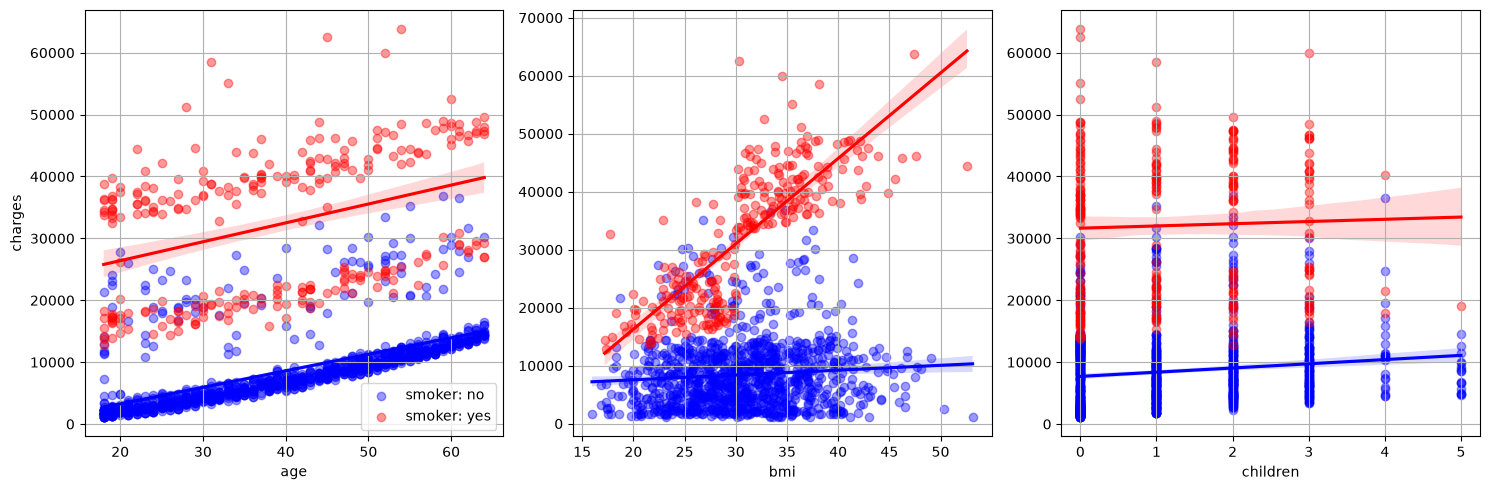

In [138]:
fig, axis = plt.subplots(1, 3, figsize=(15, 5))

#lista con las variables numericas
numericas = ["age", "bmi", "children", "charges"]

#lista de tuplas que voy a usar para graficar, separando por los posibles valores de smoker: yes o no
    #si la persona no fuma aparecera en color azul, pero si sí lo hace será rojo
ValorColor = [("no", "blue") , ("yes", "red")]

for ax, col in zip(axis, numericas): # bucle 1 para recorrer lista de numericas
    if col != "charges": # excluyo charges del bucle
        for valor, color in ValorColor: #en cada grafico se haran 2 pasos a partir de las tuplas de antes: graficar gente fumadora por un
            # lado (en azul) y la gente no fumadora por el otro (en rojo)
            filtro = df["smoker"] == valor # filtro para df segun la persona fuma o no (valor yes o no de la tupla)
            sns.regplot(ax = ax, data = df[filtro], 
                        x = col, y = "charges", color = color,
                        label = f"smoker: {valor}",  scatter_kws={'alpha': 0.4}) 
        ax.legend()
        ax.grid()

#quito las etiquetas y leyendas de los graficos 2 y 3, son innecesarias al ser exactamente iguales al grafico 1
axis[1].set_ylabel(None)
axis[2].set_ylabel(None)

axis[1].get_legend().remove()
axis[2].get_legend().remove()

#muestro graficos
plt.tight_layout()
plt.show()

- El gráfico de la edad nos revela que según la gente se va envejeciendo paga más de prima, sin importar si fuma o no. Eso sí, los fumadores pagan de base muchísimo más que los no fumadores. 


- El BMI en no fumadores no parece afectar mucho a las cantidades de prima que paga la gente, que se mantienen muy bajas. Sin embargo, cuando miramos en gente fumadora, vemos como el valor se dispara y encontramos los costes de primas más exagerados, superando los 60.000.

- El gráfico de los hijos nos indica cómo aumenta el coste de la prima según aumenta la cantidad de hijos. De nuevo, nos encontramos con que la gente fumadora paga mucho más de base en comparación a los no fumadores.

En los 3 gráficos encontramos evidencia de lo mismo: un fumador pagará muchísimo más de prima que una persona no fumadora, seguramente dado el riesgo y los problemas de salud que se atribuyen al tabaquismo.

Ahora vamos a ver la relación de variables categóricas con charges.

In [139]:
df.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 83.6 KB


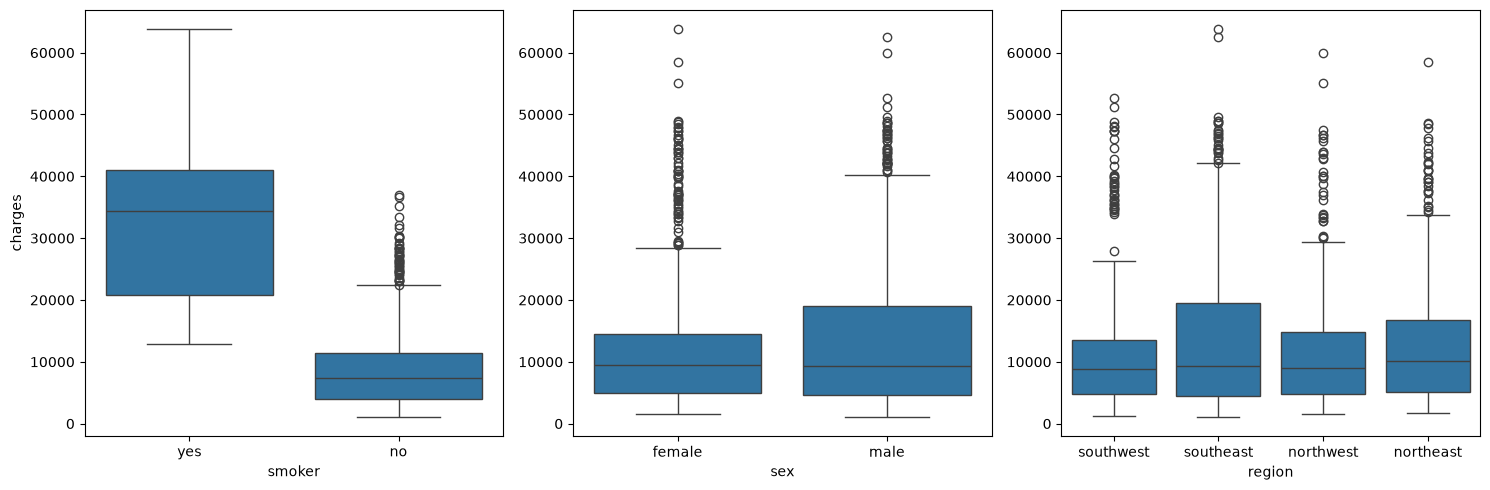

In [140]:
fig, axis = plt.subplots(1, 3, figsize=(15, 5))

categoricas = ["smoker", "sex", "region"]

for ax, col in zip(axis, categoricas):
    sns.boxplot(ax=ax, data=df, x=col, y="charges")

#quito etiqueta Y de graficos 2 y 3
axis[1].set_ylabel(None)
axis[2].set_ylabel(None)

plt.tight_layout()
plt.show()

- En cuanto a fumadores no vemos nada que no sepamos ya: la gente fumadora paga una cantidad exageradamente superior a la no fumadora.

- El sexo nos aporta algo curioso: ambos sexos parten de la misma base, sin embargo, vemos que muchos hombres acaban pagando más que sus compañeras del sexo opuesto. Esto puede deberse a que los hombres tienen mayor riesgo de mortalidad que las mujeres.

- La relación entre prima y región es una muy equilibrada, donde la gente del sureste parece ser que es la que llega a pagar más, llegando su cuartil superior a los 20.000. Aún así, todas parten más o menos de la misma base y sus cuartiles inferiores se sitúan en valores similares.

Vamos a repetir los gráficos pero esta vez añadiendo una distinción por color entre fumadores y no fumadores.

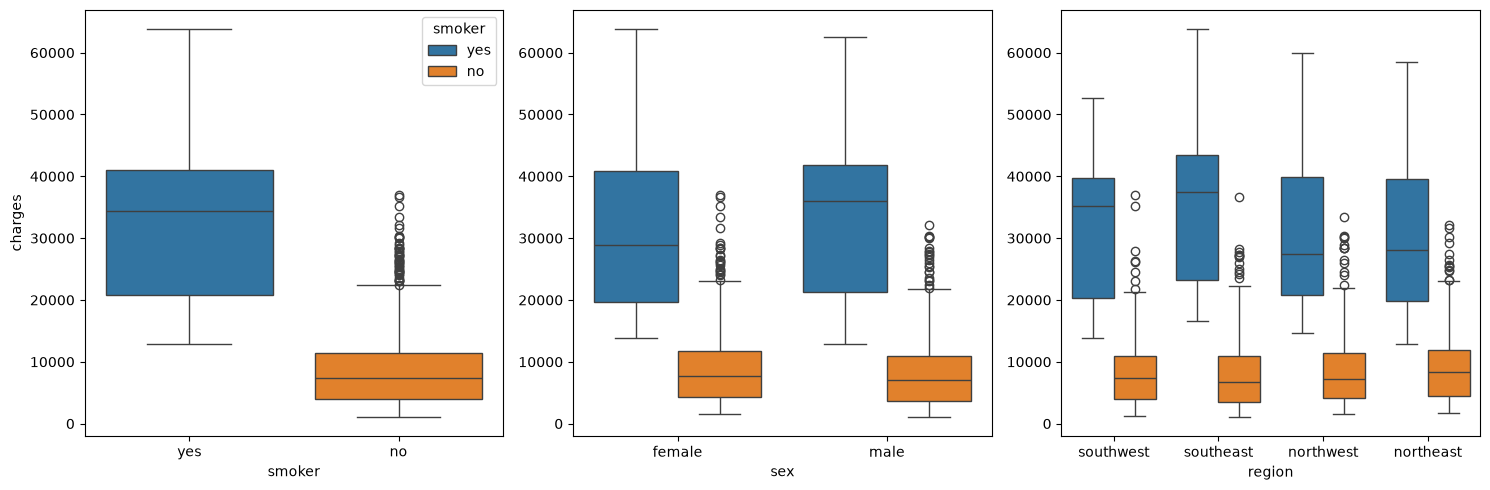

In [141]:
fig, axis = plt.subplots(1, 3, figsize=(15, 5))

categoricas = ["smoker", "sex", "region"]

for ax, col in zip(axis, categoricas):
    sns.boxplot(ax=ax, data=df, x=col, y="charges" , hue = "smoker", legend= True)

#quito etiqueta Y de graficos 2 y 3
axis[1].set_ylabel(None)
axis[2].set_ylabel(None)

axis[1].get_legend().remove()
axis[2].get_legend().remove()

plt.tight_layout()
plt.show()

Con esto reafirmamos nuestro conocimiento de que los no fumadores pagan mucho menos de base, independientemente del resto de variables.

Ahora veamos las correlaciones de las variables numéricas y charges.

In [142]:
numericas

['age', 'bmi', 'children', 'charges']

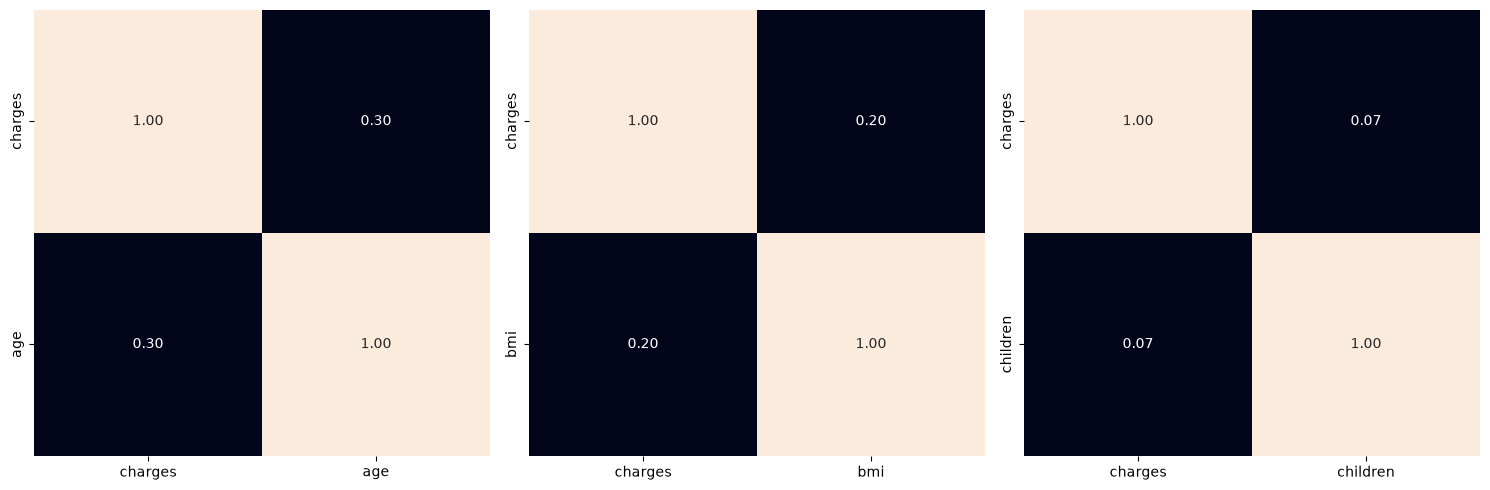

In [143]:
fig, axis = plt.subplots(1, 3, figsize = (15,5))
axis = axis.flatten()
for numerica, ax in zip(numericas, axis):
    if numerica != "charges":
        sns.heatmap(df[["charges", numerica]].corr(), annot = True, fmt = ".2f", ax = ax, cbar = False)

plt.tight_layout()
plt.show()

Encontramos que todas se relacionan directamente, aunque tampoco es que sean relaciones especialmente fuertes. La relación entre edad y prima es la más fuerte con 0,30 y la cantidad de hijos la más débil (prácticamente inexistente) con 0,07.

Vamos a terminar explorando todas las correlaciones existentes entre todas las variables. Para ello primero haremos la factorización de las no numéricas.

In [144]:
import json

# factorizo todas las variables categoricas, creando una nueva variable con sufijo "_n"
for col in categoricas:
    df[col + '_n'] = pd.factorize(df[col])[0]
    numericas.append(f"{col}_n") # añado el nombre de la nueva columna a la lista de numericas

# json con reglas de conversion
for col in categoricas:
    reglas = {row[col]: row[col + '_n'] for index, row in df[[col + '_n', col]].drop_duplicates().iterrows()}
    with open(f"./{col}_transformation_rules.json", "w") as f:
        json.dump(reglas, f)

In [145]:
numericas # voy a comprobar que he añadido las nuevas columnas a la lista de numericas

['age', 'bmi', 'children', 'charges', 'smoker_n', 'sex_n', 'region_n']

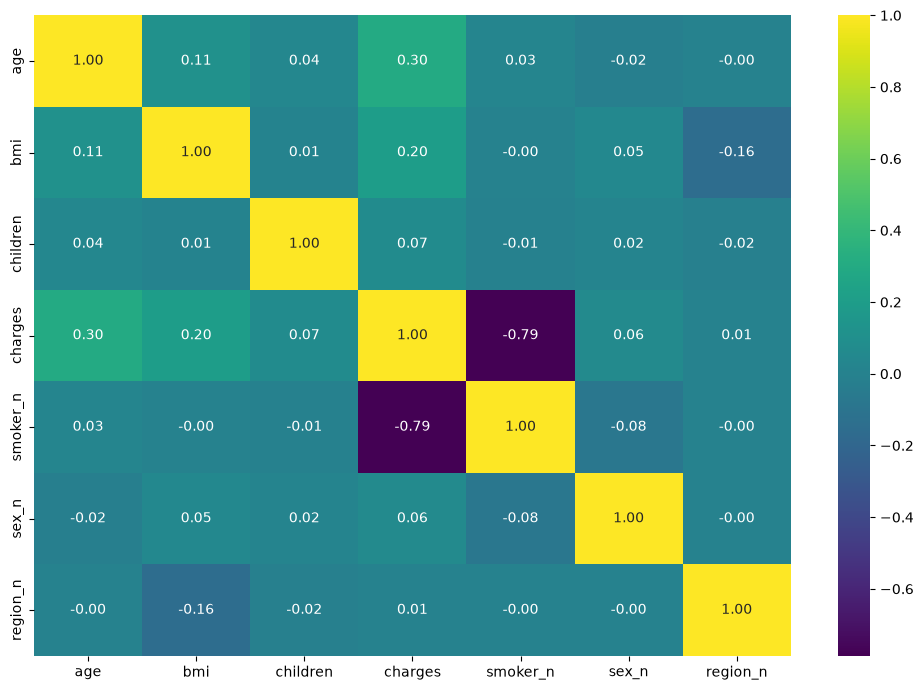

In [146]:
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(df[numericas].corr(method="pearson"), annot=True, fmt=".2f", cmap="viridis", ax=ax)
plt.tight_layout()
plt.show()

Nos reafirmamos en las conclusiones anteriores:

- Que una persona sea fumadora o no tiene un impacto brutal (-0,79) a la hora de determinar el precio de su prima.

- Quitando eso, ninguna relación llama especialmente la atención, siendo las más fuertes la edad y el índice de masa corporal.

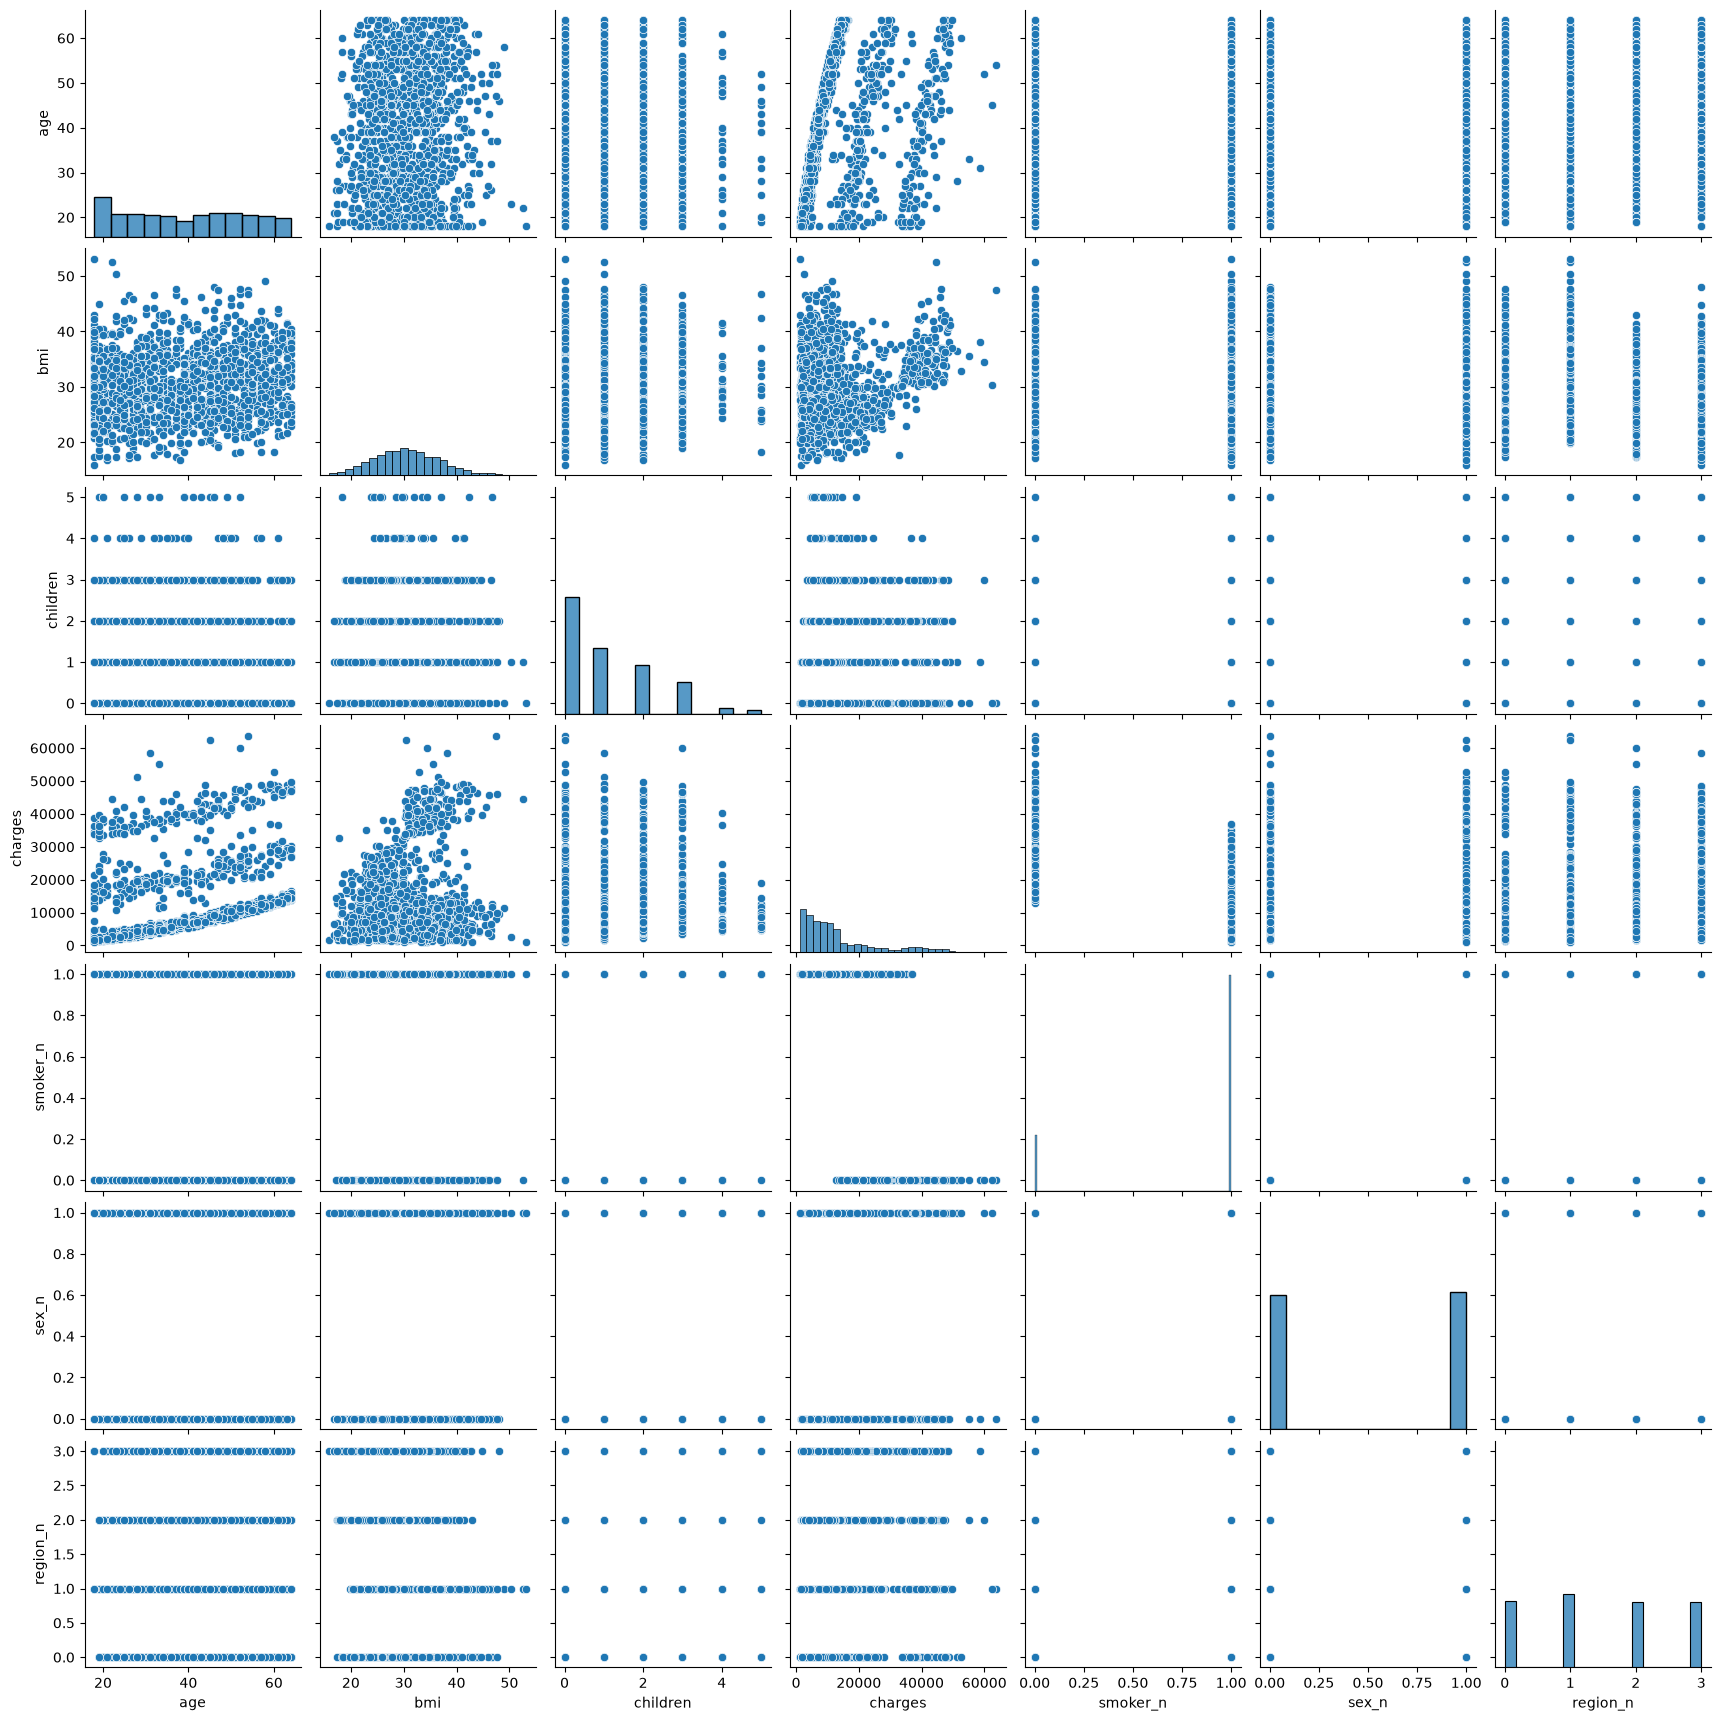

In [147]:
sns.pairplot( data = df)

## Ingeniería de características
### Tratamiento de outliers

In [148]:
# la lista de numericas ya me sirve como lista de columnas finales, pues le añadi las nuevas variables al hacer la factorizacion
#  y carece de las tipo string, por tanto voy a trabajar todo esto con ella

df = df[numericas]

df.head(3)

,age,bmi,children,charges,smoker_n,sex_n,region_n
0,19,27.90,0,16884.9240,0,0,0
1,18,33.77,1,1725.5523,1,1,1
2,28,33.00,3,4449.4620,1,1,1


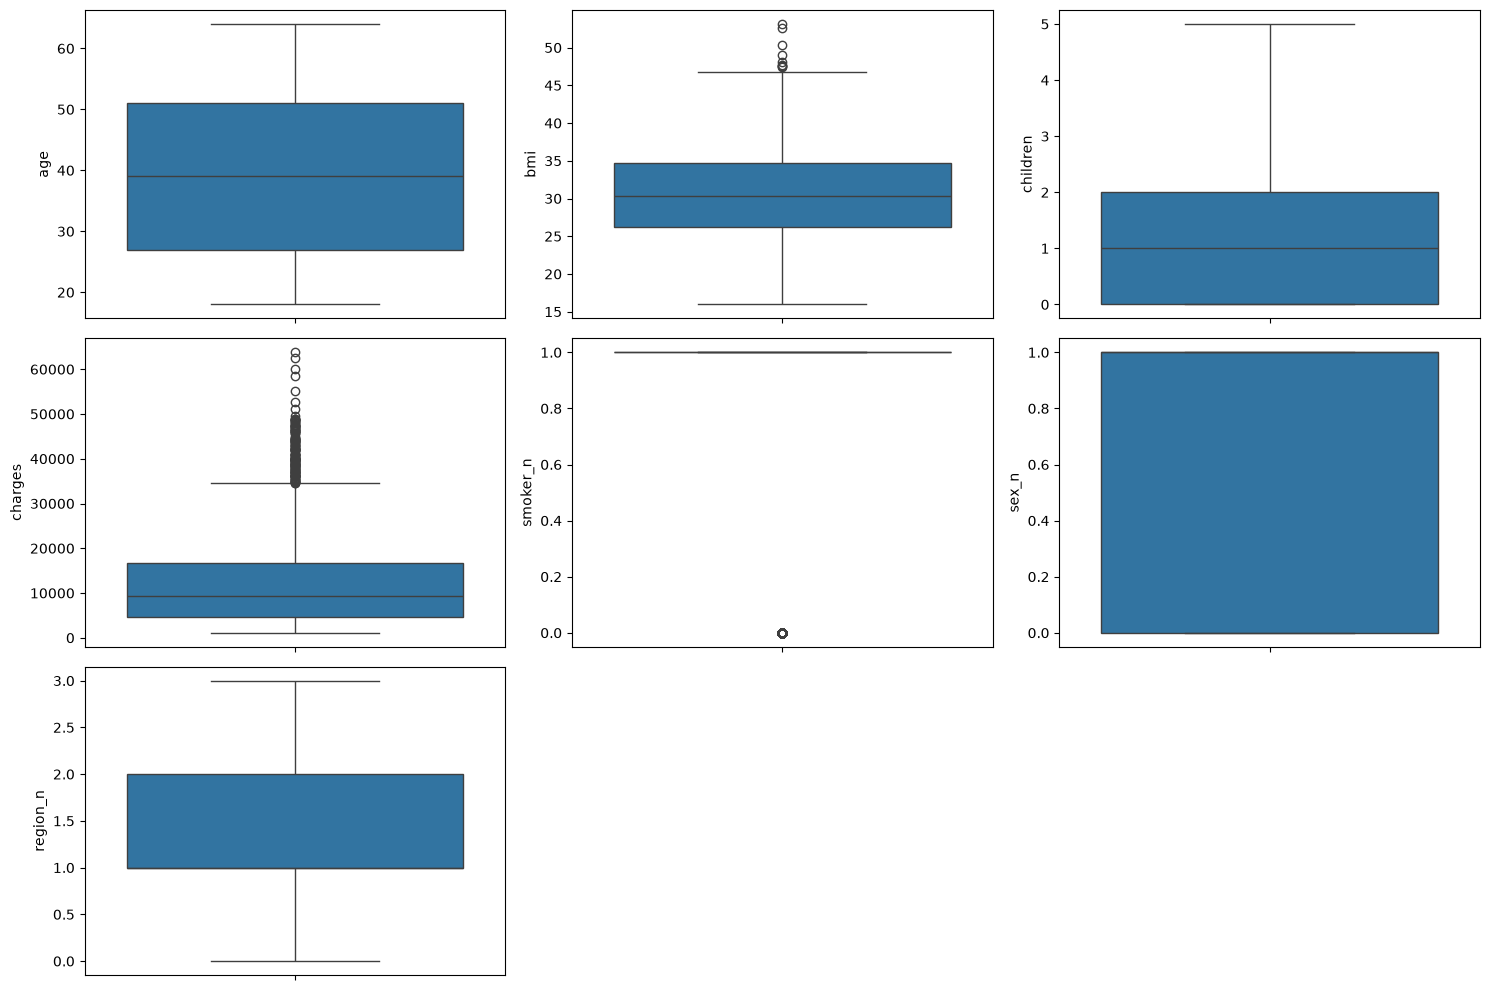

In [149]:
# voy a hacer 7 graficos para visualizar los outliers de cada variable

fig, axis = plt.subplots(3, 3, figsize = (15, 10))
axis = axis.flatten()


if "sex_n" not in df.columns:
    df["sex_n"] = df["sex"].map({"female": 0, "male": 1})
if "smoker_n" not in df.columns:
    df["smoker_n"] = df["smoker"].map({"yes": 0, "no": 1})
if "region_n" not in df.columns:
    df["region_n"] = df["region"].map({"southwest": 0, "southeast": 1, "northwest": 2, "northeast": 3})

# bucle para graficar
for ax, col in zip (axis, numericas):
    sns.boxplot(ax = ax, data = df, y = col)

#los 2 ultimos slots no tienen grafico, asi que los oculto 
axis[7].set_visible(False)
axis[8].set_visible(False)

plt.tight_layout()
plt.show()

Hay outliers en el índice de masa corporal (bmi) y la variable objetivo (charges). Sin embargo, dado el modelo que se va a crear y el caso de uso, no es conveniente eliminarlos:

- En las primas encontramos outliers que nos muestran a clientes que pagan primas increíblemente altas (35.000 o más). Pero eliminar estos outliers haría que el modelo se sobreajustara.

- Lo mismo pasa con el BMI, no hay nada que apunte a posibles errores de anotación, sino a personas reales que padezcan algún tipo de condición que les hace dar esos valores tan altos. De nuevo, eliminar estos registros supondría eliminar casos fundamentales para la determinación de primas que harían que se sobreajustara al no contar a determinados tipos de persona o situaciones.

## Preparación de los conjuntos de datos
Procedo a hacer esto directamente ya que gracias al análisis inicial sé que no hay nulos en nuestros datos.

In [150]:
from sklearn.model_selection import train_test_split

# ESTO ES LO QUE ENTRA EN ESTE PASO
# total_data

predictoras =  ["age", "bmi", "children", "sex_n", "smoker_n", "region_n"] #numericas tiene a charges, por eso no la uso para este paso 
target = "charges"

X_CON = df.drop(target, axis = 1)[predictoras]
y = df[target]

X_train_CON_outliers, X_test_CON_outliers, y_train, y_test = train_test_split(X_CON, y, test_size = 0.2, random_state = 10)


### Escalado y normalización

In [151]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

## NORMALIZACIÓN (cambiar valores para que tengan media de 0 y std de 1)
### CON OUTLIERS
norm_CON_outliers = StandardScaler()
norm_CON_outliers.fit(X_train_CON_outliers)

X_train_CON_outliers_norm = norm_CON_outliers.transform(X_train_CON_outliers)
X_train_CON_outliers_norm = pd.DataFrame(X_train_CON_outliers_norm, index = X_train_CON_outliers.index, columns = predictoras)

X_test_CON_outliers_norm = norm_CON_outliers.transform(X_test_CON_outliers)
X_test_CON_outliers_norm = pd.DataFrame(X_test_CON_outliers_norm, index = X_test_CON_outliers.index, columns = predictoras)


## ESCALADO MIN-MAX (MINMAXIMIZACIÓN) (cambiar valores para que estén comprendidos entre 0 y 1)
### CON OUTLIERS
scaler_CON_outliers = MinMaxScaler()
scaler_CON_outliers.fit(X_train_CON_outliers)

X_train_CON_outliers_scal = scaler_CON_outliers.transform(X_train_CON_outliers)
X_train_CON_outliers_scal = pd.DataFrame(X_train_CON_outliers_scal, index = X_train_CON_outliers.index, columns = predictoras)

X_test_CON_outliers_scal = scaler_CON_outliers.transform(X_test_CON_outliers)
X_test_CON_outliers_scal = pd.DataFrame(X_test_CON_outliers_scal, index = X_test_CON_outliers.index, columns = predictoras)

In [152]:
!pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable


In [153]:
# GUARDARLO -> TODO <-

# RECORDAR HABER GUARDADO LOS JSONS DE LA FACTORIZACIÓN

# PATH = "/data/processed"
PATH = "."

# DATASETS QUE HE IDO ACUMULANDO EN LOS PASOS 4 Y 5
X_train_CON_outliers.to_excel(f"{PATH}/X_train_CON_outliers.xlsx", index = False)
X_train_CON_outliers_norm.to_excel(f"{PATH}/X_train_CON_outliers_norm.xlsx", index = False)
X_train_CON_outliers_scal.to_excel(f"{PATH}/X_train_CON_outliers_scal.xlsx", index = False)

X_test_CON_outliers.to_excel(f"{PATH}/X_test_CON_outliers.xlsx", index = False)
X_test_CON_outliers_norm.to_excel(f"{PATH}/X_test_CON_outliers_norm.xlsx", index = False)
X_test_CON_outliers_scal.to_excel(f"{PATH}/X_test_CON_outliers_scal.xlsx", index = False)


y_train.to_excel(f"{PATH}/y_train.xlsx", index = False)
y_test.to_excel(f"{PATH}/y_test.xlsx", index = False)

# SCALERS
import pickle

# MODEL_PATH = "/model"
MODEL_PATH = "."

with open(f"{MODEL_PATH}/norm_CON_outliers.pkl", "wb") as file:
  pickle.dump(norm_CON_outliers, file)
with open(f"{MODEL_PATH}/scaler_CON_outliers.pkl", "wb") as file:
  pickle.dump(scaler_CON_outliers, file)

## Entrenar el modelo 

In [154]:
X_train_CON_outliers = pd.read_excel(f"{PATH}/X_train_CON_outliers.xlsx")
X_test_CON_outliers = pd.read_excel(f"{PATH}/X_test_CON_outliers.xlsx")

y_train = pd.read_excel(f"{PATH}/y_train.xlsx")
y_test = pd.read_excel(f"{PATH}/y_test.xlsx")

In [155]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = X_train_CON_outliers


model = LinearRegression().fit(X, y_train)

# vamos a ver las metricas usando el conjunto de entrenamiento
# predicts con conjunto entrenamiento
y_pred_train = model.predict(X)

# sacamos metricas
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

# las imprimimos
print("METRICAS DEL MODELO CON EL CONJUNTO DE ENTRENAMIENTO:")
print(f"RMSE (raíz del error cuadrático medio) {rmse_train:.2f}") 
print(f"Coeficiente de determinación: {r2_train:.2f}")

METRICAS DEL MODELO CON EL CONJUNTO DE ENTRENAMIENTO:
RMSE (raíz del error cuadrático medio) 6062.60
Coeficiente de determinación: 0.75


In [156]:
# ahora vamos a sacar metricas con el conjunto de test
y_pred_test = model.predict(X_test_CON_outliers)


rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print(f"METRICAS DEL MODELO CON EL CONJUNTO DE TEST:")
print(f"RMSE (raíz del error cuadrático medio) {rmse_test:.2f}") 
print(f"Coeficiente de determinación: {r2_test:.2f}")


METRICAS DEL MODELO CON EL CONJUNTO DE TEST:
RMSE (raíz del error cuadrático medio) 5992.26
Coeficiente de determinación: 0.73


## Conclusión
Hemos creado un modelo que, a falta de ser optimizado, es bastante estable ya que las métricas obtenidas utilizando los conjuntos de entrenamiento y test son muy similares.

Esto también indica que no hay apenas sobreajuste, por lo que omitir el tratamiento de outliers fue todo un acierto.